# Regresja logistyczna


**Cel:** Przewidzieć rezygnację klienta, zrozumieć prawdopodobieństwo, współczynniki i próg decyzji.



## 1. Środowisko
Jeżeli brakuje bibliotek, odkomentuj poniższą instrukcję instalacji. Instalacja wymaga internetu, sama analiza już nie. Następnie uruchom ponownie kernel.

In [1]:
# %pip install numpy pandas matplotlib scikit-learn
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'font.size': 11})
SEED = 42
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)

Python: 3.12.14 | scikit-learn: 1.8.0


## Jak działa model?
Mimo nazwy to algorytm **klasyfikacji**. Najpierw oblicza wynik liniowy $z=b+\sum_j w_j x_j$, następnie prawdopodobieństwo $p=1/(1+e^{-z})$. Dopasowanie minimalizuje log-loss z regularyzacją. Parametr `C` jest odwrotnością siły regularyzacji: mniejsze C mocniej ogranicza wagi.

Skalowanie jest częścią Pipeline i uczy się wyłącznie na treningu. Współczynnik opisuje zmianę logarytmu szans przy pozostałych cechach stałych; nie dowodzi przyczynowości.

## 2. Problem i dane
Jedna obserwacja oznacza jednego klienta. Cechy znamy w momencie prognozy, a `rezygnacja=1` oznacza odejście w następnym miesiącu. `spadek_uzycia` ma zakres 0–1; większa wartość oznacza silniejszy spadek. Dane nie zawierają przyszłych faktur ani informacji z czasu po rezygnacji.

Wszystkie trzy notebooki klasyfikacyjne generują identyczne dane i identyczny podział. Dzięki temu porównanie algorytmów jest uczciwsze.

In [2]:
rng = np.random.default_rng(SEED)
n = 1800
X = pd.DataFrame({
    'staz_mies': rng.integers(1, 73, n),
    'oplata_mies': rng.uniform(40, 220, n),
    'reklamacje': rng.poisson(0.8, n),
    'spadek_uzycia': rng.uniform(0, 1, n),
    'umowa_roczna': rng.binomial(1, 0.55, n),
    'kontakty_serwis': rng.poisson(2, n),
})
# Ukryty mechanizm służy tylko symulacji. Nie dodajemy go do cech modelu.
z = (-2.7 - 0.018 * X.staz_mies + 0.009 * X.oplata_mies
     + 0.5 * X.reklamacje + 2.3 * X.spadek_uzycia - 1.1 * X.umowa_roczna
     + 1.3 * ((X.reklamacje >= 2) & (X.spadek_uzycia > 0.6)))
p_true = 1 / (1 + np.exp(-z))
y = pd.Series(rng.binomial(1, p_true), name='rezygnacja')
display(X.head())
print('Rozmiar:', X.shape, '| Udział rezygnacji:', round(y.mean(), 3))
print('Braki danych:', X.isna().sum().sum())

Rozmiar: (1800, 6) | Udział rezygnacji: 0.293
Braki danych: 0


,staz_mies,oplata_mies,reklamacje,spadek_uzycia,umowa_roczna,kontakty_serwis
0,7,124.314995,1,0.311558,0,5
1,56,86.699171,0,0.223499,0,4
2,48,48.131161,2,0.785206,1,3
3,32,126.668441,1,0.959814,0,1
4,32,212.679823,0,0.492500,1,0


## 3. Trening, walidacja i test: 60% / 20% / 20%
Trening służy dopasowaniu parametrów; walidacja — wyborowi ustawień i progu; test — końcowej ocenie. Stratification zachowuje zbliżone proporcje klas. Losowy podział jest tu uzasadniony niezależnymi danymi syntetycznymi. W rzeczywistym churnie zastosuj walidację czasową, a powtarzających się klientów nie rozdzielaj swobodnie między zbiory.

In [3]:
from sklearn.model_selection import train_test_split
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)
print('Trening / walidacja / test:', len(X_train), len(X_val), len(X_test))
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_dev.index).isdisjoint(X_test.index)

Trening / walidacja / test: 1080 360 360


## 4. Punkt odniesienia i metryki
Accuracy to odsetek poprawnych odpowiedzi. Precision to trafność alarmów; recall to udział wykrytych rezygnacji. F1 łączy precision i recall. ROC-AUC ocenia ranking bez jednego ustalonego progu. AP (average precision) podsumowuje krzywą precision–recall; nie jest identyczne z trapezową PR-AUC.

Baseline przewiduje stałe prawdopodobieństwo równe udziałowi klasy pozytywnej na treningu. Dobry wynik powinien przewyższać tak prostą metodę.

In [4]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay, log_loss)
from sklearn.dummy import DummyClassifier

def metryki(y_true, p, prog=0.5):
    pred = (p >= prog).astype(int)
    return {'accuracy': accuracy_score(y_true, pred),
            'precision': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred, zero_division=0),
            'F1': f1_score(y_true, pred, zero_division=0),
            'ROC_AUC': roc_auc_score(y_true, p),
            'AP': average_precision_score(y_true, p)}
baseline = DummyClassifier(strategy='prior').fit(X_train, y_train)
display(pd.DataFrame([metryki(y_val, baseline.predict_proba(X_val)[:, 1])], index=['Baseline — walidacja']))

,accuracy,precision,recall,F1,ROC_AUC,AP
Baseline — walidacja,0.708333,0.0,0.0,0.0,0.5,0.291667


## 5. Uczenie i wybór ustawień na walidacji

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
wyniki, modele = [], {}
for C in [0.01, 0.1, 1.0, 10.0]:
    m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000, random_state=SEED))
    m.fit(X_train, y_train)
    modele[C] = m
    wyniki.append({'C': C, **metryki(y_val, m.predict_proba(X_val)[:, 1])})
ranking = pd.DataFrame(wyniki).sort_values('ROC_AUC', ascending=False)
display(ranking)
model = modele[float(ranking.iloc[0]['C'])]

,C,accuracy,precision,recall,F1,ROC_AUC,AP
2,1.00,0.747222,0.616667,0.352381,0.448485,0.793389,0.581419
3,10.00,0.747222,0.616667,0.352381,0.448485,0.793352,0.581392
1,0.10,0.755556,0.654545,0.342857,0.450000,0.793315,0.581881
0,0.01,0.733333,0.666667,0.171429,0.272727,0.792829,0.582635


## 6. Próg decyzji i koszt błędów
Próg 0,5 nie musi być optymalny. Przyjmujemy **wyłącznie dydaktyczne** koszty: FP=50, FN=300 jednostek, TP=TN=0. Wybieramy próg minimalizujący koszt na walidacji. To uproszczona macierz kosztów, a nie pełna kalkulacja rentowności kampanii.

In [6]:
from sklearn.metrics import confusion_matrix
p_val = model.predict_proba(X_val)[:, 1]
rows = []
for t in np.arange(0.05, 0.96, 0.05):
    tn, fp, fn, tp = confusion_matrix(y_val, (p_val >= t).astype(int), labels=[0, 1]).ravel()
    rows.append({'prog': float(t), 'koszt': 50*fp + 300*fn, 'FP': fp, 'FN': fn,
                 **metryki(y_val, p_val, t)})
progi = pd.DataFrame(rows)
best_t = float(progi.loc[progi.koszt.idxmin(), 'prog'])
display(progi.round(3))
print('Próg wybrany na walidacji:', round(best_t, 2))

Próg wybrany na walidacji: 0.15


,prog,koszt,FP,FN,accuracy,precision,recall,F1,ROC_AUC,AP
0,0.05,12250,245,0,0.319,0.300,1.000,0.462,0.793,0.581
1,0.10,10250,199,1,0.444,0.343,0.990,0.510,0.793,0.581
2,0.15,8350,149,3,0.578,0.406,0.971,0.573,0.793,0.581
3,0.20,8400,120,8,0.644,0.447,0.924,0.602,0.793,0.581
4,0.25,11200,98,21,0.669,0.462,0.800,0.585,0.793,0.581
5,0.30,13000,74,31,0.708,0.500,0.705,0.585,0.793,0.581
6,0.35,14450,61,38,0.725,0.523,0.638,0.575,0.793,0.581
7,0.40,17500,50,50,0.722,0.524,0.524,0.524,0.793,0.581
8,0.45,19500,36,59,0.736,0.561,0.438,0.492,0.793,0.581
9,0.50,21550,23,68,0.747,0.617,0.352,0.448,0.793,0.581


## 7. Końcowy test
Ustawienia i próg są już zamrożone. Oceniamy model na niewidzianych danych. Nie dopasowujemy go ponownie na treningu+walidacji, aby zachować zgodność modelu z dobranym progiem. Porównanie z 0,5 jest opisowe, nie służy kolejnemu wyborowi.

,accuracy,precision,recall,F1,ROC_AUC,AP
Baseline,0.708,0.000,0.000,0.000,0.500,0.292
"Model: próg 0,5",0.789,0.774,0.390,0.519,0.783,0.667
Model: próg z walidacji,0.531,0.373,0.895,0.527,0.783,0.667


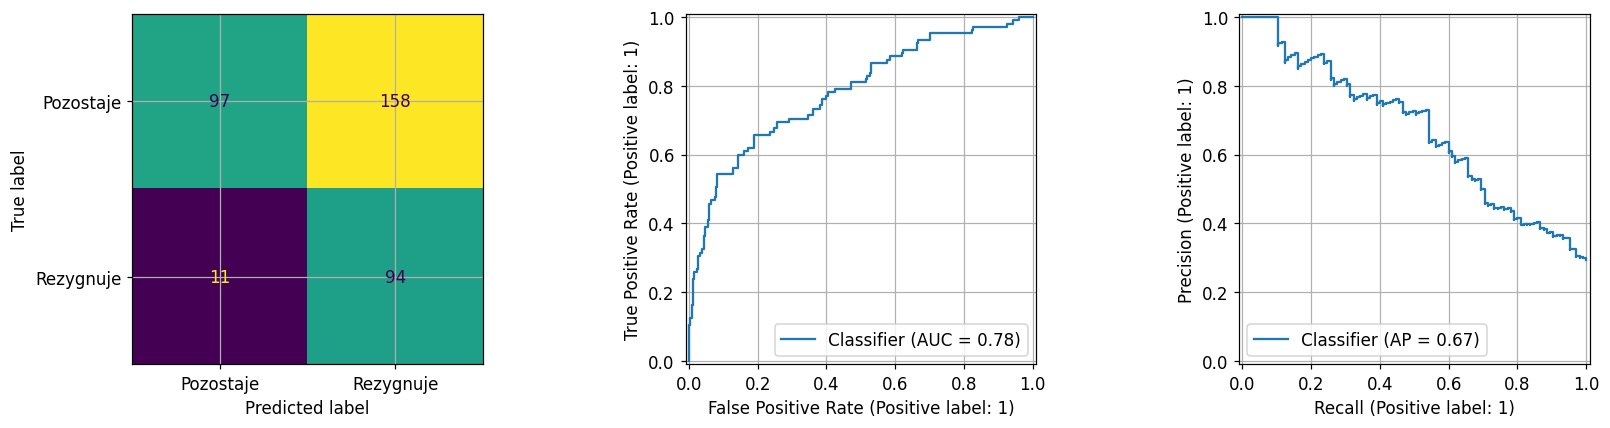

In [7]:
p_test = model.predict_proba(X_test)[:, 1]
display(pd.DataFrame([
    metryki(y_test, baseline.predict_proba(X_test)[:, 1]),
    metryki(y_test, p_test, 0.5), metryki(y_test, p_test, best_t)],
    index=['Baseline', 'Model: próg 0,5', 'Model: próg z walidacji']).round(3))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(y_test, (p_test >= best_t).astype(int),
    display_labels=['Pozostaje', 'Rezygnuje'], ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, p_test, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, p_test, ax=axes[2])
plt.tight_layout(); plt.show()

## 8. Interpretacja modelu

,cecha,waga,iloraz_szans_na_1_SD
4,umowa_roczna,-0.367420,0.692519
0,staz_mies,-0.337654,0.713442
5,kontakty_serwis,-0.042242,0.958638
1,oplata_mies,0.368097,1.444982
2,reklamacje,0.512126,1.668836
3,spadek_uzycia,0.684659,1.983096


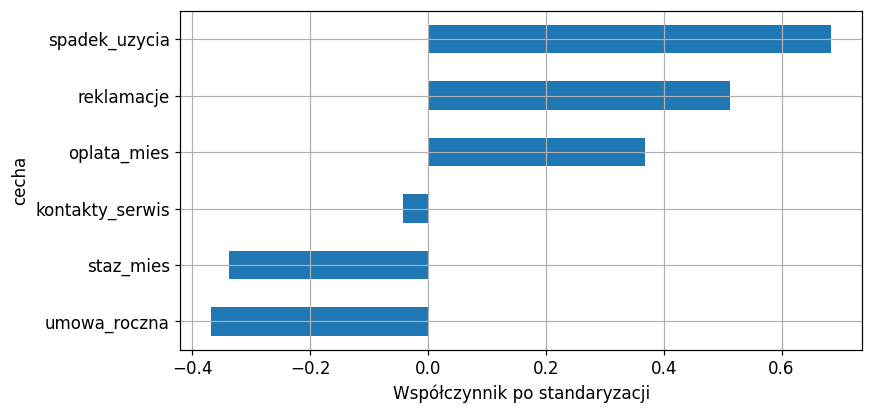

In [8]:
w = model.named_steps['logisticregression'].coef_[0]
coef = pd.DataFrame({'cecha': X.columns, 'waga': w, 'iloraz_szans_na_1_SD': np.exp(w)})
display(coef.sort_values('waga'))
coef.set_index('cecha')['waga'].sort_values().plot.barh()
plt.xlabel('Współczynnik po standaryzacji'); plt.show()

Wagi dotyczą wzrostu cechy o jedno odchylenie standardowe treningu, także dla cechy binarnej. `exp(w)` jest mnożnikiem szans, nie prawdopodobieństwa. Skorelowane cechy i regularyzacja utrudniają interpretację. Model liniowy nie odtwarza jawnie interakcji wpisanej w generator danych.

## 9. Ćwiczenia samodzielne
1. Wyjaśnij na macierzy pomyłek, co oznaczają FP i FN dla działu utrzymania klientów.
2. Zmień koszt FN z 300 na 100 i wybierz próg ponownie **na walidacji**. Co dzieje się z recall?
3. Zmień jeden parametr modelu i porównaj wynik walidacyjny z wersją bazową.
4. Usuń `spadek_uzycia`. Czy pogorszenie wyniku zgadza się z interpretacją modelu?
5. Porównaj ten notebook z pozostałymi klasyfikatorami: ROC-AUC, AP, precision i recall. Nie zakładaj, że model bardziej złożony musi wygrać.

Po obejrzeniu testu nie stroimy dalej na jego podstawie. Dalsze eksperymenty wymagają nowego nietkniętego testu lub zagnieżdżonej walidacji.

In [9]:
# Miejsce na własny eksperyment

## Wskazówki do odpowiedzi
Niższy próg zwiększa lub utrzymuje recall, ale precision nie musi zmieniać się monotonicznie. Droższe FN zwykle sprzyjają niższemu progowi. Usunięcie informacji może pogorszyć model, lecz wynik na małej próbie nie jest gwarantowany. Ranking modeli dotyczy tych danych i tego podziału, nie wszystkich problemów.

**Najważniejsze:** model uczy się na treningu, decyzje projektowe podejmujemy na walidacji, a końcowy wynik raportujemy na teście.